# GeoMobility360 AI — J2 : nettoyage et analyse géographique avec Python

## 1.1. Import des bibliothèques

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"

In [2]:

from pathlib import Path
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt


## 1.2. Charger le fichier GEOJSON

In [7]:

# À adapter à l'emplacement réel de ton projet
projet = Path(r"D:\Projets_Data\GeoMobility360_AI")

fichier = projet / "data" / "raw" / "communes_idf.geojson"

print("Fichier trouvé :", fichier.is_file())

if not fichier.is_file():
    raise FileNotFoundError(f"Fichier introuvable : {fichier}")

communes = gpd.read_file(fichier)

print("Nombre de communes : ", communes.shape[0])

print("Nombre de colonnes : ", communes.shape[1])

print("Nom de colonnes : ", communes.columns)

display(communes.head())


Skipping field codesPostaux: unsupported OGR type: 5


Fichier trouvé : True
Nombre de communes :  1266
Nombre de colonnes :  8
Nom de colonnes :  Index(['nom', 'code', 'codeDepartement', 'siren', 'codeEpci', 'codeRegion',
       'population', 'geometry'],
      dtype='object')


,nom,code,codeDepartement,siren,codeEpci,codeRegion,population,geometry
0,Paris,75056,75,217500016,200054781,11,2103778,"POLYGON ((2.35198 48.90148, 2.35524 48.90155, ..."
1,Achères-la-Forêt,77001,77,217700012,200072346,11,1191,"POLYGON ((2.55546 48.37128, 2.55603 48.37126, ..."
2,Amillis,77002,77,217700020,200090504,11,830,"POLYGON ((3.12671 48.7053, 3.12605 48.70543, 3..."
3,Amponville,77003,77,217700038,200023240,11,349,"POLYGON ((2.503 48.2851, 2.50287 48.28591, 2.5..."
4,Andrezel,77004,77,217700046,200070779,11,336,"POLYGON ((2.76939 48.60338, 2.76667 48.60525, ..."


## 2. Contrôle de la qualité des données

In [8]:

# Vérifier les codes INSEE en double
doublons = communes["code"].duplicated().sum()

print("Nombre de doublons :", doublons)


Nombre de doublons : 0


In [13]:
print("Nombre de valeurs manquantes : ", communes.isna().sum().sum())

Nombre de valeurs manquantes :  0


In [10]:
print("Nombre de géométries manquantes : ", communes["geometry"].isna().sum())

Nombre de géométries manquantes :  0


In [14]:
print("Nombre de géométries vides : ", communes["geometry"].isnull().sum())

Nombre de géométries vides :  0


In [20]:
invalides = (
    ~communes.geometry.is_valid
    & communes.geometry.notna()
)

print("Nombre de géométries invalides :", invalides.sum())

Nombre de géométries invalides : 0


## 3. Inspecter les anomalies détectées

In [29]:

masque_invalides = (
    ~communes.geometry.is_valid
    & ~communes.geometry.isna()
    & ~communes.geometry.is_empty
)

display(
    communes.loc[
        masque_invalides,
        ["code", "nom", "geometry"]
    ].head()
)


,code,nom,geometry


## 4. Comprendre les systèmes de coordonnées

In [30]:
#Vérifier la projection actuelle
print("Projection actuelle :", communes.crs)


Projection actuelle : EPSG:4326


In [31]:

# Reprojection des données en Lambert-93
communes_m = communes.to_crs(epsg=2154)

print("Nouvelle projection :", communes_m.crs.to_epsg())


Nouvelle projection : 2154


## 5. Calculer les superficies communales

In [32]:

# Calculer les superficies en m²
surfaces_m2 = communes_m.geometry.area

# Afficher les 5 premières valeurs
print(surfaces_m2.head())


0    1.054316e+08
1    1.260897e+07
2    2.014615e+07
3    1.192794e+07
4    8.078441e+06
dtype: float64


In [36]:
# Créer la colonne "surface_km2"

communes_m["surface_km2"] = communes_m.geometry.area/1000000

In [38]:
#Afficher les colonnes nom et surface_km2

communes_m[["code", "nom", "surface_km2"]]

,code,nom,surface_km2
0,75056,Paris,105.431575
1,77001,Achères-la-Forêt,12.608975
2,77002,Amillis,20.146149
3,77003,Amponville,11.927941
4,77004,Andrezel,8.078441
...,...,...,...
1261,95676,Villers-en-Arthies,8.326818
1262,95678,Villiers-Adam,9.857781
1263,95680,Villiers-le-Bel,7.319379
1264,95682,Villiers-le-Sec,3.244726


In [46]:
#Afficher les communes les plus étendues en terme de superficie

communes_m.nlargest(5, "surface_km2")

,nom,code,codeDepartement,siren,codeEpci,codeRegion,population,geometry,surface_km2
176,Fontainebleau,77186,77,217701861,200072346,11,15583,"POLYGON ((681333.5 6820366.939, 681364.825 682...",172.286640
0,Paris,75056,75,217500016,200054781,11,2103778,"POLYGON ((652494.134 6867026.311, 652732.809 6...",105.431575
719,Saint-Germain-en-Laye,78551,78,200086924,200058519,11,45931,"POLYGON ((631938.114 6872236.164, 631982.709 6...",53.133708
103,Chenoise-Cucharmoy,77109,77,200084036,200037133,11,1607,"POLYGON ((710295.666 6833293.601, 710286.067 6...",48.747991
737,Sonchamp,78601,78,217806017,200073344,11,1678,"POLYGON ((613844.104 6829888.889, 613867.498 6...",46.349321


In [47]:
#Analyser la superficie des communes franciliennes


print("Surface minimale :", communes_m["surface_km2"].min())
print("Surface maximale :", communes_m["surface_km2"].max())

print(
    "Surfaces nulles ou négatives :",
    (communes_m["surface_km2"] <= 0).sum()
)

print(
    "Surfaces manquantes :",
    communes_m["surface_km2"].isna().sum()
)


Surface minimale : 0.09721130200873633
Surface maximale : 172.28663969215648
Surfaces nulles ou négatives : 0
Surfaces manquantes : 0


## 6. Créer une carte choroplèthe

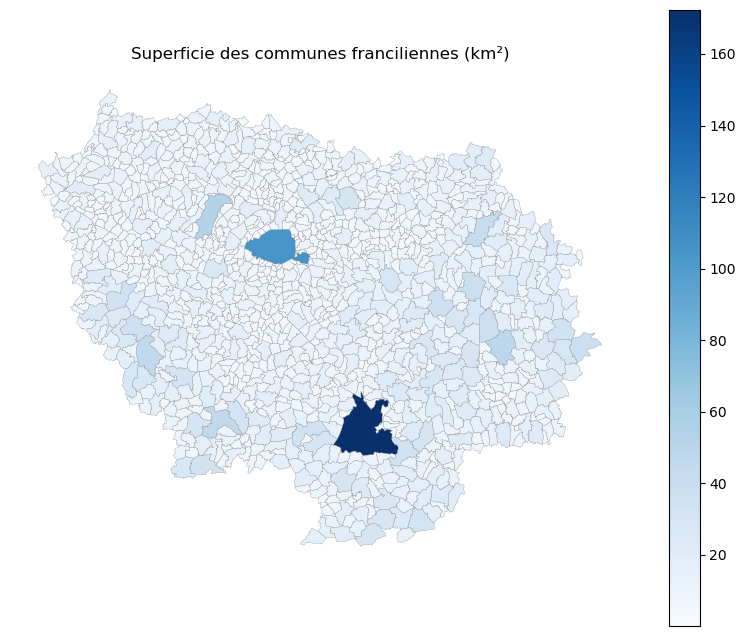

In [52]:

fig, ax = plt.subplots(figsize=(10, 8))

communes_m.plot(
    column="surface_km2",
    cmap="Blues",
    legend=True,
    edgecolor="grey",
    linewidth=0.2,
    ax=ax
)

ax.set_title("Superficie des communes franciliennes (km²)")
ax.axis("off")

plt.show()


## 7. Exporter la carte

In [53]:

destination = projet / "reports" / "figures"
destination.mkdir(parents=True, exist_ok=True)

fig.savefig(
    destination / "J02_superficies_communes_idf.png",
    dpi=150,
    bbox_inches="tight"
)


## 8. Data Visualisation avancée

In [54]:

import importlib.util

for module in ["plotly", "folium", "mapclassify"]:
    etat = "Installé" if importlib.util.find_spec(module) else "Absent"
    print(module, ":", etat)


plotly : Installé
folium : Installé
mapclassify : Installé


### 8.1. Créer un graphique interactif avec Plotly

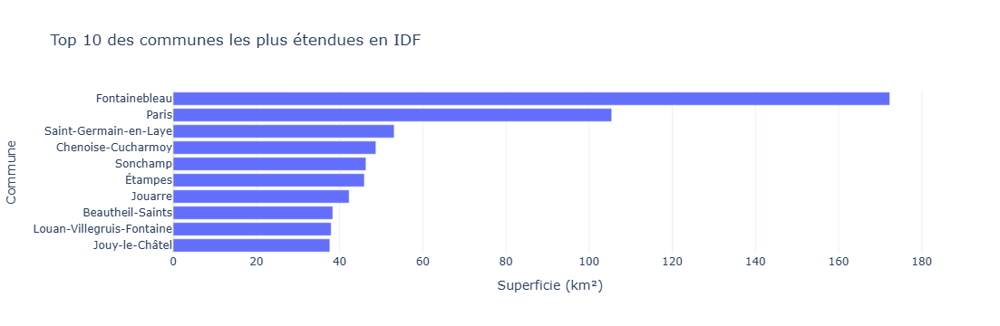

In [55]:

import plotly.express as px

# Les 10 communes les plus étendues
top10 = communes_m.nlargest(10, "surface_km2")

fig = px.bar(
    top10,
    x="surface_km2",
    y="nom",
    orientation="h",
    title="Top 10 des communes les plus étendues en IDF",
    labels={
        "surface_km2": "Superficie (km²)",
        "nom": "Commune"
    },
    template="plotly_white"
)

fig.update_yaxes(autorange="reversed")
fig.show()


## 8.2. Créer une carte choroplèthe interactive avec Folium

In [57]:

# Préparer une version géographique en WGS84
communes_web = communes_m.to_crs(epsg=4326)

# Créer la carte interactive
carte = communes_web.explore(
    column="surface_km2",
    cmap="YlGnBu",
    tooltip=["nom", "surface_km2"],
    legend=True,
    tiles="OpenStreetMap"
)

carte


In [63]:
#Sauvegarder la carte 


carte.save(
    "D:/Projets_Data/GeoMobility360_AI/reports/figures/J02_carte_interactive_communes.html"
)
